# 10.4 Negative Sampling — Word2Vec 🧠

Negative Sampling is a technique that makes Word2Vec training more computationally efficient by learning to distinguish genuine word–context pairs from randomly sampled pairs.

To understand why it exists, remember that Skip-gram tries to predict context words from a target word.

## 1. Why does Negative Sampling exist?

Imagine a vocabulary containing 100,000 words. With a traditional softmax output, predicting the next context word involves calculating scores across the entire vocabulary.

Doing this repeatedly can be computationally expensive.

Negative Sampling simplifies the training task: instead of predicting probabilities for every vocabulary word, the model learns to distinguish:

- Positive pairs: A target word and a context word that actually occur together.
- Negative pairs: A target word and a sampled word that is used as a contrastive example.

Target word: `drinks`

Positive pair

`(drinks, milk)`

Negative pair

`(drinks, airplane)`

Illustrative examples: the model learns to score genuine pairs higher than sampled negative pairs.

## 2. Online visual explanation

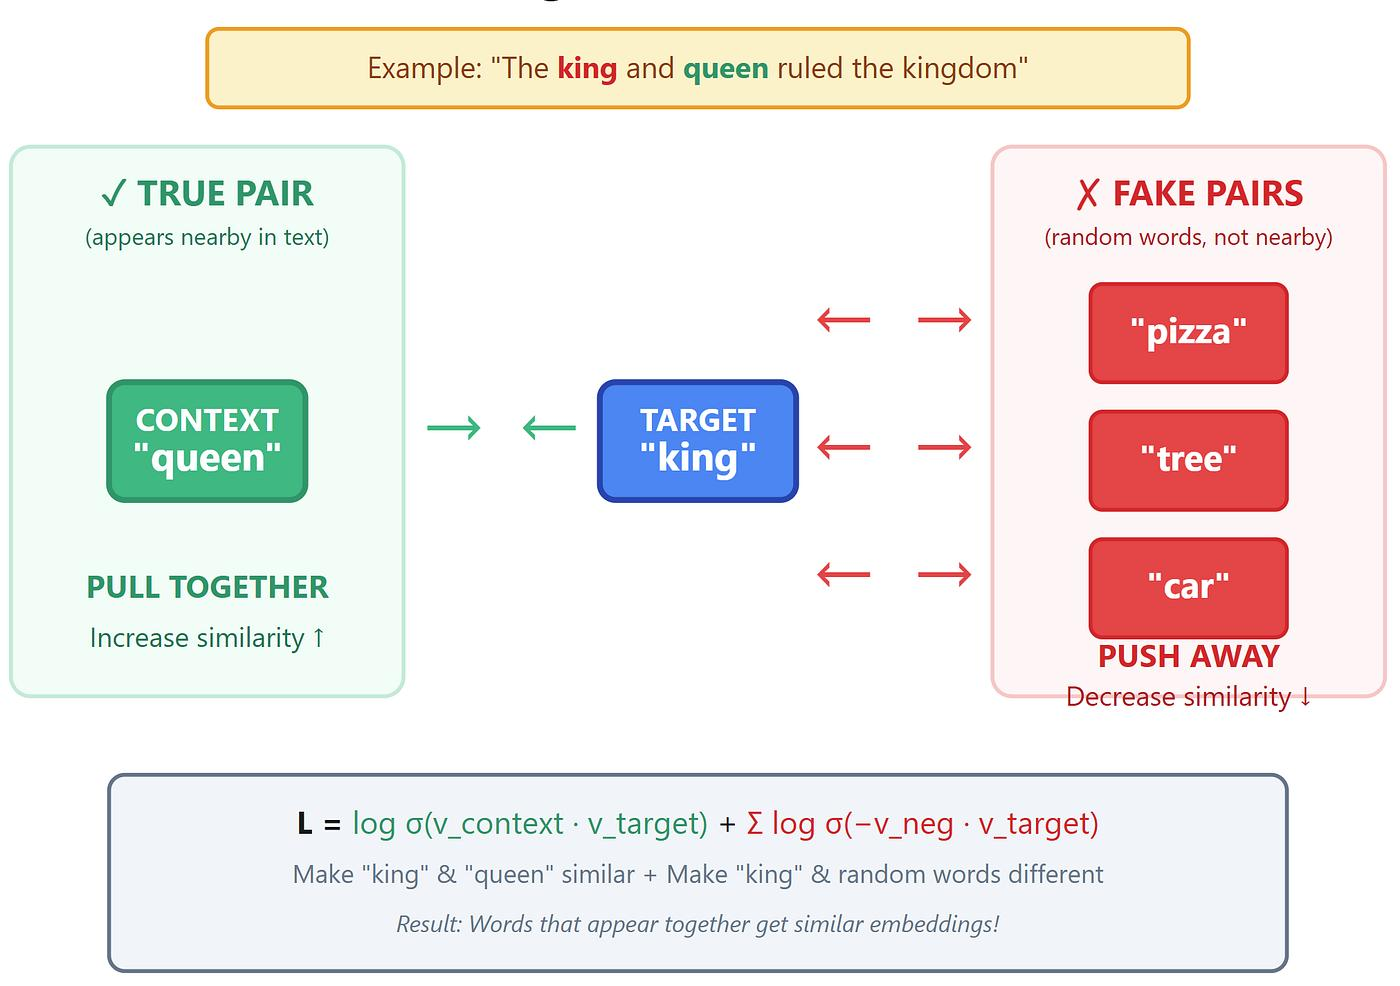

These diagrams illustrate how Skip-gram with Negative Sampling (SGNS) trains on observed pairs and sampled negative pairs.

## 3. Positive pairs

Positive pairs come from actual neighboring words in the training corpus.

Consider:

> “The cat drinks fresh milk.”

With a context window of 2, examples around `drinks` include:

| Target word | Context word | Label |
| ----------- | ------------ | ----- |
| drinks      | cat          | 1     |
| drinks      | fresh        | 1     |
| drinks      | milk         | 1     |

The label `1` means the pair is a genuine observed target–context pair.

## 4. Negative pairs

Negative pairs are generated by sampling words to pair with the target word. They do not represent observed positive pairs for that training example.

For example:

| Target word | Sampled word | Label |
| ----------- | ------------ | ----- |
| drinks      | airplane     | 0     |
| drinks      | keyboard     | 0     |
| drinks      | mountain     | 0     |

The label `0` means the pair is being used as a negative training example.

Important: A sampled negative pair is not necessarily impossible or meaningless in natural language. It is a contrastive example for the model.

## 5. How the model learns

Positive pair: `(drinks, milk)`

The model adjusts its vectors to increase the pair's compatibility score.

Negative pair: `(drinks, airplane)`

The model adjusts its vectors to decrease the pair's compatibility score.

Repeat across training data

The embedding weights gradually learn useful word relationships.

Mathematically, the SGNS objective for one positive pair and \\(K\\) sampled negative words is:

$$
\log \sigma(\mathbf{v}_w^\top \mathbf{u}_c)
+ \sum_{i=1}^{K} \log \sigma(-\mathbf{v}_w^\top \mathbf{u}_{n_i})
$$

Here:

- \\(\mathbf{v}\_w\\): target-word vector
- \\(\mathbf{u}\_c\\): positive context vector
- \\(\mathbf{u}\_{n_i}\\): sampled negative-word vector
- \\(\sigma\\): sigmoid function
- \\(K\\): number of negative samples

You don't need to memorize this formula yet. The essential idea is to increase positive-pair scores and decrease negative-pair scores.

## 6. Key takeaways 🎯

- Why it exists: Reduces the computational cost of Word2Vec training compared with full-vocabulary softmax.
- Positive pairs: Genuine target–context pairs from the corpus.
- Negative pairs: Sampled contrasts used during training.
- Result: The model learns word vectors that capture useful statistical relationships.

---